Total messages: 5572
Data loaded successfully!
Training samples: 4457
Validation samples: 1115
Creating TF-IDF features...
Feature extraction completed in 0.05 seconds
Feature matrix shape: (4457, 3000)

Training Logistic Regression model...
Training completed in 0.01 seconds

Traditional NLP Model Results:
Accuracy:  0.9749
Precision: 1.0000
Recall:    0.8121
F1 Score:  0.8963


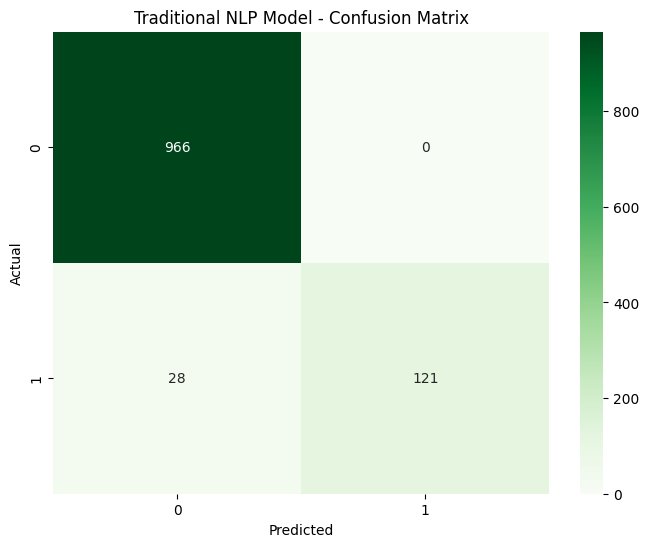


Detailed Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       1.00      0.81      0.90       149

    accuracy                           0.97      1115
   macro avg       0.99      0.91      0.94      1115
weighted avg       0.98      0.97      0.97      1115


Testing on sample messages:

Message: "WINNER!! You have won a $1000 prize! Call now!"
Prediction: spam

Message: "Hey, are we still meeting for lunch tomorrow?"
Prediction: ham

Top 10 words indicating SPAM:
  txt: 4.3902
  mobile: 3.5444
  uk: 3.4748
  claim: 3.3800
  www: 3.2361
  reply: 3.1788
  150p: 2.9043
  free: 2.8308
  service: 2.8300
  stop: 2.6764

Top 10 words indicating HAM:
  ok: -1.7803
  ll: -1.5871
  da: -1.4231
  gt: -1.4037
  lt: -1.3868
  come: -1.3535
  home: -1.3463
  got: -1.2783
  lt gt: -1.2217
  lor: -1.2073

TRADITIONAL NLP MODEL SUMMARY
Feature extraction time: 0.05 seconds
Training time: 0.01 seconds
T

In [1]:
# TRADITIONAL NLP MODEL: SMS SPAM DETECTION
# Using TF-IDF + Logistic Regression


# Import libraries
# Importing everything I need for traditional NLP
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import time

#Load the data
# Loading the same SMS spam dataset
df = pd.read_csv('SMSSpamCollection', sep='\t', names=['label', 'message'])

# Convert labels to binary (0=ham, 1=spam)
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(f'Total messages: {len(df)}')
print(f'Data loaded successfully!')

#  Split the data
# Using same split as deep learning model (80/20)
X_train, X_valid, y_train, y_valid = train_test_split(
    df['message'], 
    df['label'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df['label']
)

print(f'Training samples: {len(X_train)}')
print(f'Validation samples: {len(X_valid)}')

#  Create TF-IDF features
# Converting text to numerical features using TF-IDF
# TF-IDF measures how important words are in each message
print('Creating TF-IDF features...')
start_time = time.time()

tfidf = TfidfVectorizer(
    max_features=3000,  # Keep top 3000 words
    ngram_range=(1, 2),  # Use single words and pairs
    min_df=2,  # Word must appear in at least 2 documents
    stop_words='english'  # Remove common words like 'the', 'a'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_valid_tfidf = tfidf.transform(X_valid)

feature_time = time.time() - start_time
print(f'Feature extraction completed in {feature_time:.2f} seconds')
print(f'Feature matrix shape: {X_train_tfidf.shape}')

# Train Logistic Regression model
# Training a simple but effective classifier
print('\nTraining Logistic Regression model...')
start_time = time.time()

model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    C=1.0  # Regularization strength
)

model.fit(X_train_tfidf, y_train)

train_time = time.time() - start_time
print(f'Training completed in {train_time:.2f} seconds')

# Make predictions
# Testing the model on validation data
y_pred = model.predict(X_valid_tfidf)

# Calculate metrics
# Getting accuracy, precision, recall, and F1 score
accuracy = accuracy_score(y_valid, y_pred)
precision = precision_score(y_valid, y_pred)
recall = recall_score(y_valid, y_pred)
f1 = f1_score(y_valid, y_pred)

print('\nTraditional NLP Model Results:')
print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1 Score:  {f1:.4f}')

#  Show confusion matrix
# Visualizing model performance
cm = confusion_matrix(y_valid, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title('Traditional NLP Model - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

#  Detailed classification report
# Breaking down performance by class
print('\nDetailed Classification Report:')
print(classification_report(y_valid, y_pred, target_names=['ham', 'spam']))

# Test on sample messages
# Trying the model on real examples
print('\nTesting on sample messages:\n')

# Test spam message
spam_test = "WINNER!! You have won a $1000 prize! Call now!"
spam_tfidf = tfidf.transform([spam_test])
spam_pred = model.predict(spam_tfidf)[0]
print(f'Message: "{spam_test}"')
print(f'Prediction: {"spam" if spam_pred == 1 else "ham"}')
print()

# Test ham message
ham_test = "Hey, are we still meeting for lunch tomorrow?"
ham_tfidf = tfidf.transform([ham_test])
ham_pred = model.predict(ham_tfidf)[0]
print(f'Message: "{ham_test}"')
print(f'Prediction: {"spam" if ham_pred == 1 else "ham"}')
print()

# Show most important features
# Looking at which words indicate spam
feature_names = tfidf.get_feature_names_out()
coefficients = model.coef_[0]

# Top spam indicators
top_spam_idx = coefficients.argsort()[-10:][::-1]
print('Top 10 words indicating SPAM:')
for idx in top_spam_idx:
    print(f'  {feature_names[idx]}: {coefficients[idx]:.4f}')

print()

# Top ham indicators
top_ham_idx = coefficients.argsort()[:10]
print('Top 10 words indicating HAM:')
for idx in top_ham_idx:
    print(f'  {feature_names[idx]}: {coefficients[idx]:.4f}')

# Summary statistics
# Comparing training time and effort
print('\n' + '='*50)
print('TRADITIONAL NLP MODEL SUMMARY')
print('='*50)
print(f'Feature extraction time: {feature_time:.2f} seconds')
print(f'Training time: {train_time:.2f} seconds')
print(f'Total time: {feature_time + train_time:.2f} seconds')
print(f'Number of features: {X_train_tfidf.shape[1]}')
print(f'Model complexity: Simple (Logistic Regression)')
print(f'Final accuracy: {accuracy:.4f}')

# Saving the trained model and vectorizer
import pickle

# Save model
with open('spam_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# Save vectorizer
with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print('Model saved as spam_model.pkl')
print('Vectorizer saved as vectorizer.pkl')